In [1]:
%%capture
!pip uninstall -y numpy pandas scipy scikit-image
!pip install -q numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 scikit-image==0.24.0
!pip install -q ultralytics simple-lama-inpainting lpips opencv-python-headless Pillow matplotlib tqdm


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, shutil, zipfile, random, math, time
from pathlib import Path

PROJECT_NAME = "cse498r_instance_removal_week_update"
BASE_DIR     = Path("/content") / PROJECT_NAME
DATA_DIR     = BASE_DIR / "data"
WORK_DIR     = BASE_DIR / "work"
OUT_DIR      = BASE_DIR / "outputs"
PLOT_DIR     = OUT_DIR / "plots"
VIS_DIR      = OUT_DIR / "selected_visuals"
TMP_DIR      = BASE_DIR / "tmp"

for d in [DATA_DIR, WORK_DIR, OUT_DIR, PLOT_DIR, VIS_DIR, TMP_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DRIVE_ROOT = Path("/content/drive/MyDrive") / PROJECT_NAME
DRIVE_OUT  = DRIVE_ROOT / "outputs"
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

print("BASE_DIR  :", BASE_DIR)
print("DRIVE_OUT :", DRIVE_OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_DIR  : /content/cse498r_instance_removal_week_update
DRIVE_OUT : /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs


In [3]:
from google.colab import files
import os

print("Please upload your dataset zip file (example: coco_200_persons.zip)")
uploaded = files.upload()

ZIP_PATH = list(uploaded.keys())[0]
assert os.path.exists(ZIP_PATH), f"Dataset zip not found: {ZIP_PATH}"

print("Using uploaded zip:", ZIP_PATH)


Please upload your dataset zip file (example: coco_200_persons.zip)


Saving coco_200_persons.zip to coco_200_persons (1).zip
Using uploaded zip: coco_200_persons (1).zip


In [4]:
import zipfile, json
from pathlib import Path

EXTRACT_ROOT = DATA_DIR / "dataset_extracted"
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

# Extract only once in current session
if len(list(EXTRACT_ROOT.rglob("*"))) == 0:
    print("Extracting dataset zip...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_ROOT)
else:
    print("Dataset already extracted in this session.")

# Find all images recursively
all_images = sorted(list(EXTRACT_ROOT.rglob("*.jpg"))) + sorted(list(EXTRACT_ROOT.rglob("*.png"))) + sorted(list(EXTRACT_ROOT.rglob("*.jpeg")))
print("Total images found:", len(all_images))

assert len(all_images) > 0, "No images found after extraction. Check zip structure."

# Try to find metadata.json anywhere inside extracted folder
metadata_files = list(EXTRACT_ROOT.rglob("metadata.json"))
if len(metadata_files) > 0:
    metadata_path = metadata_files[0]
    with open(metadata_path, "r") as f:
        metadata = json.load(f)
    print("Metadata loaded from:", metadata_path)
    print("Metadata entries:", len(metadata))
else:
    metadata = []
    print("No metadata.json found. Continuing without metadata.")


Dataset already extracted in this session.
Total images found: 200
Metadata loaded from: /content/cse498r_instance_removal_week_update/data/dataset_extracted/metadata.json
Metadata entries: 200


In [5]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from tqdm.auto import tqdm

from ultralytics import YOLO
from simple_lama_inpainting import SimpleLama
import lpips

from skimage.metrics import peak_signal_noise_ratio as psnr_fn
from skimage.metrics import structural_similarity as ssim_fn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
DEVICE: cuda
GPU: Tesla T4
VRAM(GB): 14.56


In [6]:
%%time
print("Loading YOLOv8x-seg...")
yolo_seg = YOLO("yolov8x-seg.pt")

print("Loading SimpleLaMa...")
lama = SimpleLama()

print("Loading LPIPS...")
lpips_fn = lpips.LPIPS(net='alex').to(DEVICE).eval()

print("All models loaded.")


Loading YOLOv8x-seg...


Downloading: "https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt" to /root/.cache/torch/hub/checkpoints/big-lama.pt


Loading SimpleLaMa...


100%|██████████| 196M/196M [00:00<00:00, 221MB/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading LPIPS...
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 91.1MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
All models loaded.
CPU times: user 2.88 s, sys: 1.36 s, total: 4.24 s
Wall time: 7.16 s


In [7]:
# =========================
# DATA / EXPERIMENT CONTROL
# =========================
MAX_IMAGES                = None      # None = all
MAX_PERSONS               = 8
YOLO_CONF                 = 0.35
MIN_MASK_AREA             = 1200
SAVE_ONLY_SELECTED_VISUALS = True
NUM_VISUAL_SAMPLES_BEST   = 12
NUM_VISUAL_SAMPLES_WORST  = 8
NUM_VISUAL_SAMPLES_RANDOM = 8

# =========================
# TUNING CONTROL
# =========================
USE_TUNING_SEARCH         = True
TUNE_IMAGES               = 30        # small subset for config search
TUNE_STRIDE               = 1
TOPK_CONFIGS_TO_KEEP      = 3

# =========================
# ADAPTIVE MASK PARAMETERS
# =========================
CONFIG_GRID = [
    {
        "name": "cfg_smallpad",
        "dilate_frac": 0.035,
        "dilate_min": 7,
        "dilate_max": 31,
        "blur_frac": 0.020,
        "blur_min": 5,
        "blur_max": 21,
        "crop_pad_frac": 0.18,
        "crop_pad_min": 24,
        "crop_pad_max": 160
    },
    {
        "name": "cfg_midpad",
        "dilate_frac": 0.050,
        "dilate_min": 9,
        "dilate_max": 41,
        "blur_frac": 0.025,
        "blur_min": 7,
        "blur_max": 25,
        "crop_pad_frac": 0.22,
        "crop_pad_min": 32,
        "crop_pad_max": 192
    },
    {
        "name": "cfg_bigpad",
        "dilate_frac": 0.065,
        "dilate_min": 11,
        "dilate_max": 51,
        "blur_frac": 0.030,
        "blur_min": 9,
        "blur_max": 29,
        "crop_pad_frac": 0.28,
        "crop_pad_min": 40,
        "crop_pad_max": 256
    }
]

# =========================
# RESUME / FILES
# =========================
RESULTS_CSV = OUT_DIR / "metrics_ABC.csv"
SUMMARY_JSON = OUT_DIR / "summary_ABC.json"
TUNE_CSV     = OUT_DIR / "tuning_results.csv"

print("Number of configs:", len(CONFIG_GRID))
print("Results CSV:", RESULTS_CSV)


Number of configs: 3
Results CSV: /content/cse498r_instance_removal_week_update/outputs/metrics_ABC.csv


In [8]:
def ensure_odd(x: int) -> int:
    x = int(max(1, x))
    return x if x % 2 == 1 else x + 1

def clamp(v, lo, hi):
    return max(lo, min(hi, v))

def read_rgb(path):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise ValueError(f"Failed to read image: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def to_lpips_tensor(img_rgb):
    arr = img_rgb.astype(np.float32) / 127.5 - 1.0
    ten = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    return ten

def bbox_from_mask(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return None
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def expand_box(x1, y1, x2, y2, H, W, pad):
    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(W - 1, x2 + pad)
    y2 = min(H - 1, y2 + pad)
    return x1, y1, x2, y2

def crop_with_box(img, box):
    x1, y1, x2, y2 = box
    return img[y1:y2+1, x1:x2+1]

def paste_with_soft_mask(base_rgb, patch_rgb, full_mask):
    alpha = (full_mask.astype(np.float32) / 255.0)[..., None]
    out = patch_rgb.astype(np.float32) * alpha + base_rgb.astype(np.float32) * (1 - alpha)
    return np.clip(out, 0, 255).astype(np.uint8)

def composite_score(mean_psnr, mean_ssim, mean_lpips):
    # higher is better
    return mean_psnr + 15.0 * mean_ssim - 10.0 * mean_lpips


In [9]:
def detect_and_segment(image_rgb, yolo_conf=YOLO_CONF, min_mask_area=MIN_MASK_AREA, max_persons=MAX_PERSONS):
    H, W = image_rgb.shape[:2]
    results = yolo_seg(image_rgb, conf=yolo_conf, classes=[0], verbose=False)[0]

    persons = []
    if results.masks is None or results.boxes is None:
        return persons

    masks_data = results.masks.data.cpu().numpy()
    boxes_data = results.boxes.xyxy.cpu().numpy()
    confs_data = results.boxes.conf.cpu().numpy() if results.boxes.conf is not None else np.ones(len(boxes_data))

    for i in range(len(boxes_data)):
        mask_small = masks_data[i]
        mask_full = cv2.resize(mask_small, (W, H), interpolation=cv2.INTER_LINEAR)
        binary = (mask_full > 0.5).astype(np.uint8) * 255
        area = int(binary.sum() / 255)

        if area < min_mask_area:
            continue

        x1, y1, x2, y2 = map(int, boxes_data[i])
        conf = float(confs_data[i])

        persons.append({
            "bbox": [x1, y1, x2, y2],
            "mask": binary,
            "area": area,
            "conf": conf,
            "cx": (x1 + x2) / 2.0,
            "cy": (y1 + y2) / 2.0,
        })

    persons.sort(key=lambda p: p["area"], reverse=True)
    return persons[:max_persons]


In [10]:
def adaptive_mask_params(person, image_shape, cfg):
    H, W = image_shape[:2]
    x1, y1, x2, y2 = person["bbox"]
    bw = max(1, x2 - x1 + 1)
    bh = max(1, y2 - y1 + 1)
    ref = max(bw, bh)

    dilate_k = ensure_odd(clamp(int(ref * cfg["dilate_frac"]), cfg["dilate_min"], cfg["dilate_max"]))
    blur_k   = ensure_odd(clamp(int(ref * cfg["blur_frac"]),   cfg["blur_min"],   cfg["blur_max"]))
    crop_pad = int(clamp(ref * cfg["crop_pad_frac"], cfg["crop_pad_min"], cfg["crop_pad_max"]))

    return dilate_k, blur_k, crop_pad

def refine_person_mask(mask, dilate_k, blur_k):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilate_k, dilate_k))
    dilated = cv2.dilate(mask, kernel, iterations=1)

    feather = cv2.GaussianBlur(dilated.astype(np.float32), (blur_k, blur_k), 0)
    out = (feather > 127).astype(np.uint8) * 255
    return out

def sort_persons(persons, image_shape, strategy="largest_first"):
    if strategy == "largest_first":
        return sorted(persons, key=lambda p: p["area"], reverse=True)

    elif strategy == "center_first":
        H, W = image_shape[:2]
        cx0, cy0 = W / 2.0, H / 2.0
        return sorted(
            persons,
            key=lambda p: ((p["cx"] - cx0) ** 2 + (p["cy"] - cy0) ** 2)
        )

    elif strategy == "confidence_first":
        return sorted(persons, key=lambda p: p["conf"], reverse=True)

    return persons


In [17]:
def lama_inpaint_rgb(image_rgb, mask):
    """
    Inpaint image_rgb using SimpleLaMa.
    Always force the returned image to match the input spatial size.
    """
    pil_img = Image.fromarray(image_rgb)
    pil_mask = Image.fromarray(mask)
    result = lama(pil_img, pil_mask)
    out = np.array(result.convert("RGB"))

    # Safety resize in case model output size changes slightly
    if out.shape[:2] != image_rgb.shape[:2]:
        out = cv2.resize(out, (image_rgb.shape[1], image_rgb.shape[0]), interpolation=cv2.INTER_LINEAR)

    return out


def local_crop_inpaint(image_rgb, person, cfg):
    H, W = image_rgb.shape[:2]
    dilate_k, blur_k, crop_pad = adaptive_mask_params(person, image_rgb.shape, cfg)

    refined_mask = refine_person_mask(person["mask"], dilate_k, blur_k)
    box = bbox_from_mask(refined_mask)
    if box is None:
        return image_rgb.copy(), np.zeros((H, W), dtype=np.uint8), None

    x1, y1, x2, y2 = box
    x1, y1, x2, y2 = expand_box(x1, y1, x2, y2, H, W, crop_pad)

    crop_img = image_rgb[y1:y2+1, x1:x2+1].copy()
    crop_mask = refined_mask[y1:y2+1, x1:x2+1].copy()

    # Inpaint crop
    inpainted_crop = lama_inpaint_rgb(crop_img, crop_mask)

    # Extra safety: make sure result exactly matches crop size
    ch, cw = crop_img.shape[:2]
    if inpainted_crop.shape[:2] != (ch, cw):
        inpainted_crop = cv2.resize(inpainted_crop, (cw, ch), interpolation=cv2.INTER_LINEAR)

    # Soft blending mask
    blur_for_blend = ensure_odd(max(5, blur_k))
    crop_mask_soft = cv2.GaussianBlur(
        crop_mask.astype(np.float32),
        (blur_for_blend, blur_for_blend),
        0
    )
    crop_mask_soft = np.clip(crop_mask_soft, 0, 255).astype(np.uint8)

    # Safety: ensure soft mask size matches crop
    if crop_mask_soft.shape[:2] != (ch, cw):
        crop_mask_soft = cv2.resize(crop_mask_soft, (cw, ch), interpolation=cv2.INTER_LINEAR)

    orig_crop = image_rgb[y1:y2+1, x1:x2+1]

    alpha = (crop_mask_soft.astype(np.float32) / 255.0)[..., None]

    mixed_crop = np.clip(
        inpainted_crop.astype(np.float32) * alpha +
        orig_crop.astype(np.float32) * (1 - alpha),
        0, 255
    ).astype(np.uint8)

    out = image_rgb.copy()
    out[y1:y2+1, x1:x2+1] = mixed_crop

    full_mask = np.zeros((H, W), dtype=np.uint8)
    full_mask[y1:y2+1, x1:x2+1] = crop_mask

    info = {
        "dilate_k": dilate_k,
        "blur_k": blur_k,
        "crop_pad": crop_pad,
        "crop_box": [x1, y1, x2, y2]
    }
    return out, full_mask, info


In [18]:
def method_A_single_shot_global(image_rgb, persons, cfg):
    H, W = image_rgb.shape[:2]
    union_mask = np.zeros((H, W), dtype=np.uint8)

    for p in persons:
        dilate_k, blur_k, _ = adaptive_mask_params(p, image_rgb.shape, cfg)
        m = refine_person_mask(p["mask"], dilate_k, blur_k)
        union_mask = np.maximum(union_mask, m)

    t0 = time.time()
    result = lama_inpaint_rgb(image_rgb, union_mask)
    return {
        "result": result,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3)
    }

def method_B_progressive_global(image_rgb, persons, cfg, sort_strategy="largest_first"):
    H, W = image_rgb.shape[:2]
    current = image_rgb.copy()
    union_mask = np.zeros((H, W), dtype=np.uint8)
    steps = []

    ordered = sort_persons(persons, image_rgb.shape, strategy=sort_strategy)

    t0 = time.time()
    for p in ordered:
        dilate_k, blur_k, _ = adaptive_mask_params(p, image_rgb.shape, cfg)
        m = refine_person_mask(p["mask"], dilate_k, blur_k)
        union_mask = np.maximum(union_mask, m)
        current = lama_inpaint_rgb(current, m)
        steps.append(current.copy())

    return {
        "result": current,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3),
        "n_steps": len(steps)
    }

def method_C_progressive_local(image_rgb, persons, cfg, sort_strategy="largest_first"):
    H, W = image_rgb.shape[:2]
    current = image_rgb.copy()
    union_mask = np.zeros((H, W), dtype=np.uint8)
    steps = []
    step_info = []

    ordered = sort_persons(persons, image_rgb.shape, strategy=sort_strategy)

    t0 = time.time()
    for p in ordered:
        current, local_mask, info = local_crop_inpaint(current, p, cfg)
        union_mask = np.maximum(union_mask, local_mask)
        steps.append(current.copy())
        step_info.append(info)

    return {
        "result": current,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3),
        "n_steps": len(steps),
        "step_info": step_info
    }


In [19]:
def compute_metrics(original, reconstructed, mask):
    """
    Proxy metrics inside the edited region.
    Note: these are background-consistency / image-preservation proxy metrics,
    not true ground-truth reconstruction metrics.
    """
    m = mask > 127
    if not m.any():
        return {
            "PSNR": 0.0,
            "SSIM": 0.0,
            "LPIPS": 1.0,
            "mask_coverage_%": 0.0
        }

    ys, xs = np.where(m)
    y1, y2 = ys.min(), ys.max()
    x1, x2 = xs.min(), xs.max()

    orig_c  = original[y1:y2+1, x1:x2+1]
    recon_c = reconstructed[y1:y2+1, x1:x2+1]

    if orig_c.shape[0] < 8 or orig_c.shape[1] < 8:
        return {
            "PSNR": 0.0,
            "SSIM": 0.0,
            "LPIPS": 1.0,
            "mask_coverage_%": round(float(100.0 * m.sum() / m.size), 3)
        }

    psnr_val = psnr_fn(orig_c, recon_c, data_range=255)
    ssim_val = ssim_fn(orig_c, recon_c, channel_axis=2, data_range=255)

    with torch.no_grad():
        lp = lpips_fn(to_lpips_tensor(orig_c), to_lpips_tensor(recon_c)).item()

    return {
        "PSNR": round(float(psnr_val), 4),
        "SSIM": round(float(ssim_val), 4),
        "LPIPS": round(float(lp), 4),
        "mask_coverage_%": round(float(100.0 * m.sum() / m.size), 3)
    }


def residual_person_score(image_rgb, conf=0.25):
    """
    Runs person detection again on the final image.
    Lower remaining persons / lower confidence means better removal.
    """
    results = yolo_seg(image_rgb, conf=conf, classes=[0], verbose=False)[0]

    if results.boxes is None or len(results.boxes) == 0:
        return {
            "remaining_persons": 0,
            "remaining_conf_sum": 0.0,
            "remaining_max_conf": 0.0
        }

    confs = results.boxes.conf.cpu().numpy() if results.boxes.conf is not None else np.ones(len(results.boxes))
    return {
        "remaining_persons": int(len(confs)),
        "remaining_conf_sum": round(float(confs.sum()), 4),
        "remaining_max_conf": round(float(confs.max()) if len(confs) > 0 else 0.0, 4)
    }


def overlay_detections(image_rgb, persons):
    vis = image_rgb.copy()
    for i, p in enumerate(persons):
        x1, y1, x2, y2 = p["bbox"]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 80), 3)
        cv2.putText(
            vis,
            f"P{i+1}",
            (x1 + 4, y1 + 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (0, 255, 80),
            2
        )
    return vis


def overlay_mask(image_rgb, persons):
    vis = image_rgb.copy().astype(np.float32)
    for p in persons:
        alpha = (p["mask"] / 255.0)[..., None]
        green = np.zeros_like(vis)
        green[..., 1] = 255
        vis = vis * (1 - 0.40 * alpha) + green * (0.40 * alpha)
    return np.clip(vis, 0, 255).astype(np.uint8)


def save_visual_grid(stem, original, persons, outA, outB, outC, mA, mB, mC, save_path):
    det = overlay_detections(original, persons)
    seg = overlay_mask(original, persons)

    # residual person detection on outputs
    rA = residual_person_score(outA["result"])
    rB = residual_person_score(outB["result"])
    rC = residual_person_score(outC["result"])

    fig, axes = plt.subplots(1, 6, figsize=(36, 6))
    fig.suptitle(f"{stem} | {len(persons)} detected person(s) in input", fontsize=14, fontweight="bold")

    def show(ax, img, title):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    show(axes[0], original, "Original")
    show(axes[1], det, "Detection")
    show(axes[2], seg, "Segmentation mask")

    show(
        axes[3],
        outA["result"],
        "A: Single-shot\n"
        f"PSNR={mA['PSNR']} | SSIM={mA['SSIM']} | LPIPS={mA['LPIPS']}\n"
        f"Remain={rA['remaining_persons']} | ConfSum={rA['remaining_conf_sum']}"
    )

    show(
        axes[4],
        outB["result"],
        "B: Progressive-global\n"
        f"PSNR={mB['PSNR']} | SSIM={mB['SSIM']} | LPIPS={mB['LPIPS']}\n"
        f"Remain={rB['remaining_persons']} | ConfSum={rB['remaining_conf_sum']}"
    )

    show(
        axes[5],
        outC["result"],
        "C: Progressive-local\n"
        f"PSNR={mC['PSNR']} | SSIM={mC['SSIM']} | LPIPS={mC['LPIPS']}\n"
        f"Remain={rC['remaining_persons']} | ConfSum={rC['remaining_conf_sum']}"
    )

    plt.tight_layout()
    plt.savefig(save_path, dpi=170, bbox_inches="tight")
    plt.close(fig)


In [20]:
def pick_tuning_subset(image_paths, n=TUNE_IMAGES):
    if n is None or n >= len(image_paths):
        return image_paths
    idxs = np.linspace(0, len(image_paths) - 1, n).astype(int)
    return [image_paths[i] for i in idxs]


def evaluate_one_image_for_tuning(img_path, cfg):
    image_rgb = read_rgb(img_path)
    persons = detect_and_segment(image_rgb)

    if len(persons) == 0:
        return None

    outB = method_B_progressive_global(
        image_rgb, persons, cfg, sort_strategy="largest_first"
    )
    outC = method_C_progressive_local(
        image_rgb, persons, cfg, sort_strategy="largest_first"
    )

    mB = compute_metrics(image_rgb, outB["result"], outB["union_mask"])
    mC = compute_metrics(image_rgb, outC["result"], outC["union_mask"])

    rB = residual_person_score(outB["result"])
    rC = residual_person_score(outC["result"])

    return {
        "image": Path(img_path).stem,
        "n_persons": len(persons),

        "B_PSNR": mB["PSNR"],
        "B_SSIM": mB["SSIM"],
        "B_LPIPS": mB["LPIPS"],
        "B_remaining_persons": rB["remaining_persons"],
        "B_remaining_conf_sum": rB["remaining_conf_sum"],

        "C_PSNR": mC["PSNR"],
        "C_SSIM": mC["SSIM"],
        "C_LPIPS": mC["LPIPS"],
        "C_remaining_persons": rC["remaining_persons"],
        "C_remaining_conf_sum": rC["remaining_conf_sum"],

        "dPSNR": mC["PSNR"] - mB["PSNR"],
        "dSSIM": mC["SSIM"] - mB["SSIM"],
        "dLPIPS": mC["LPIPS"] - mB["LPIPS"],

        # lower is better for these two
        "dRemainPersons": rC["remaining_persons"] - rB["remaining_persons"],
        "dRemainConf": rC["remaining_conf_sum"] - rB["remaining_conf_sum"],
    }


tune_summary = []
best_cfg = CONFIG_GRID[0]

if USE_TUNING_SEARCH:
    tune_subset = pick_tuning_subset(all_images, TUNE_IMAGES)
    print("Tuning subset size:", len(tune_subset))

    for cfg in CONFIG_GRID:
        rows = []
        print(f"\nTesting config: {cfg['name']}")

        for img_path in tqdm(tune_subset):
            try:
                row = evaluate_one_image_for_tuning(img_path, cfg)
                if row is not None:
                    rows.append(row)
            except Exception as e:
                print("Error on", img_path, "->", e)

        if len(rows) == 0:
            continue

        df = pd.DataFrame(rows)

        mean_dpsnr = df["dPSNR"].mean()
        mean_dssim = df["dSSIM"].mean()
        mean_dlpips = df["dLPIPS"].mean()
        mean_dremain_persons = df["dRemainPersons"].mean()
        mean_dremain_conf = df["dRemainConf"].mean()

        # Higher score is better.
        # We reward better proxy metrics and strongly reward lower residual detections.
        score = (
            mean_dpsnr
            + 15.0 * mean_dssim
            - 10.0 * mean_dlpips
            - 2.0 * mean_dremain_persons
            - 1.0 * mean_dremain_conf
        )

        tune_summary.append({
            "config_name": cfg["name"],
            "mean_dPSNR_C_minus_B": round(float(mean_dpsnr), 5),
            "mean_dSSIM_C_minus_B": round(float(mean_dssim), 5),
            "mean_dLPIPS_C_minus_B": round(float(mean_dlpips), 5),
            "mean_dRemainPersons_C_minus_B": round(float(mean_dremain_persons), 5),
            "mean_dRemainConf_C_minus_B": round(float(mean_dremain_conf), 5),
            "score": round(float(score), 5)
        })

    if len(tune_summary) == 0:
        print("No valid tuning results found. Falling back to first config.")
        best_cfg = CONFIG_GRID[0]
    else:
        tune_df = pd.DataFrame(tune_summary).sort_values("score", ascending=False)
        display(tune_df)
        tune_df.to_csv(TUNE_CSV, index=False)

        best_name = tune_df.iloc[0]["config_name"]
        best_cfg = [c for c in CONFIG_GRID if c["name"] == best_name][0]
        print("\nBest config selected:", best_cfg["name"])
else:
    print("Tuning disabled. Using first config.")
    best_cfg = CONFIG_GRID[0]

print("Final config for full run:", best_cfg)


Tuning subset size: 30

Testing config: cfg_smallpad


  0%|          | 0/30 [00:00<?, ?it/s]


Testing config: cfg_midpad


  0%|          | 0/30 [00:00<?, ?it/s]


Testing config: cfg_bigpad


  0%|          | 0/30 [00:00<?, ?it/s]

,config_name,mean_dPSNR_C_minus_B,mean_dSSIM_C_minus_B,mean_dLPIPS_C_minus_B,mean_dRemainPersons_C_minus_B,mean_dRemainConf_C_minus_B,score
1,cfg_midpad,0.91406,0.14039,-0.08253,-0.2,-0.06488,4.31009
0,cfg_smallpad,0.95870,0.14645,-0.08421,0.2,0.05201,3.54556
2,cfg_bigpad,0.89298,0.13771,-0.08027,0.1,0.06071,3.50067



Best config selected: cfg_midpad
Final config for full run: {'name': 'cfg_midpad', 'dilate_frac': 0.05, 'dilate_min': 9, 'dilate_max': 41, 'blur_frac': 0.025, 'blur_min': 7, 'blur_max': 25, 'crop_pad_frac': 0.22, 'crop_pad_min': 32, 'crop_pad_max': 192}


In [21]:
rows = []
selected_images = all_images[:MAX_IMAGES] if MAX_IMAGES is not None else all_images

print("Running full evaluation on", len(selected_images), "images")
skipped = 0
failed = 0

for img_path in tqdm(selected_images):
    stem = Path(img_path).stem
    try:
        image_rgb = read_rgb(img_path)
        persons = detect_and_segment(image_rgb)

        if len(persons) == 0:
            skipped += 1
            continue

        outA = method_A_single_shot_global(
            image_rgb, persons, best_cfg
        )
        outB = method_B_progressive_global(
            image_rgb, persons, best_cfg, sort_strategy="largest_first"
        )
        outC = method_C_progressive_local(
            image_rgb, persons, best_cfg, sort_strategy="largest_first"
        )

        mA = compute_metrics(image_rgb, outA["result"], outA["union_mask"])
        mB = compute_metrics(image_rgb, outB["result"], outB["union_mask"])
        mC = compute_metrics(image_rgb, outC["result"], outC["union_mask"])

        rA = residual_person_score(outA["result"])
        rB = residual_person_score(outB["result"])
        rC = residual_person_score(outC["result"])

        rows.append({
            "image": stem,
            "n_persons": len(persons),

            "A_PSNR": mA["PSNR"],
            "A_SSIM": mA["SSIM"],
            "A_LPIPS": mA["LPIPS"],
            "A_time_s": outA["time_s"],
            "A_mask_cov": mA["mask_coverage_%"],
            "A_remaining_persons": rA["remaining_persons"],
            "A_remaining_conf_sum": rA["remaining_conf_sum"],
            "A_remaining_max_conf": rA["remaining_max_conf"],

            "B_PSNR": mB["PSNR"],
            "B_SSIM": mB["SSIM"],
            "B_LPIPS": mB["LPIPS"],
            "B_time_s": outB["time_s"],
            "B_mask_cov": mB["mask_coverage_%"],
            "B_remaining_persons": rB["remaining_persons"],
            "B_remaining_conf_sum": rB["remaining_conf_sum"],
            "B_remaining_max_conf": rB["remaining_max_conf"],

            "C_PSNR": mC["PSNR"],
            "C_SSIM": mC["SSIM"],
            "C_LPIPS": mC["LPIPS"],
            "C_time_s": outC["time_s"],
            "C_mask_cov": mC["mask_coverage_%"],
            "C_remaining_persons": rC["remaining_persons"],
            "C_remaining_conf_sum": rC["remaining_conf_sum"],
            "C_remaining_max_conf": rC["remaining_max_conf"],

            "dPSNR_C_minus_B": mC["PSNR"] - mB["PSNR"],
            "dSSIM_C_minus_B": mC["SSIM"] - mB["SSIM"],
            "dLPIPS_C_minus_B": mC["LPIPS"] - mB["LPIPS"],
            "dRemainPersons_C_minus_B": rC["remaining_persons"] - rB["remaining_persons"],
            "dRemainConf_C_minus_B": rC["remaining_conf_sum"] - rB["remaining_conf_sum"],
        })

    except Exception as e:
        failed += 1
        print("Error on", img_path, "->", e)

df = pd.DataFrame(rows)
df.to_csv(RESULTS_CSV, index=False)

print("Done.")
print("Processed:", len(df))
print("Skipped (no person):", skipped)
print("Failed:", failed)
display(df.head())


Running full evaluation on 200 images


  0%|          | 0/200 [00:00<?, ?it/s]

Done.
Processed: 200
Skipped (no person): 0
Failed: 0


,image,n_persons,A_PSNR,A_SSIM,A_LPIPS,A_time_s,A_mask_cov,A_remaining_persons,A_remaining_conf_sum,A_remaining_max_conf,...,C_time_s,C_mask_cov,C_remaining_persons,C_remaining_conf_sum,C_remaining_max_conf,dPSNR_C_minus_B,dSSIM_C_minus_B,dLPIPS_C_minus_B,dRemainPersons_C_minus_B,dRemainConf_C_minus_B
0,000000001000,8,12.8891,0.4888,0.5568,0.224,45.400,3,1.9854,0.8542,...,0.455,45.400,5,3.1575,0.8760,-0.0542,-0.0029,-0.0116,1,0.3997
1,000000002685,7,14.0302,0.4315,0.4133,0.199,45.776,0,0.0000,0.0000,...,0.679,45.776,1,0.7224,0.7224,1.2245,0.2921,-0.1585,-3,-1.6111
2,000000004134,8,12.4008,0.4101,0.4950,0.151,62.113,6,2.4882,0.5260,...,0.461,62.113,8,4.1310,0.7746,1.1556,0.1426,-0.1160,-3,-0.0187
3,000000005001,8,11.2807,0.4833,0.4198,0.168,57.741,13,6.8865,0.8073,...,0.562,57.741,9,5.1464,0.8097,0.1387,-0.0064,-0.0086,-1,-0.1539
4,000000005193,6,14.7002,0.4293,0.4068,0.154,41.601,0,0.0000,0.0000,...,0.396,41.601,0,0.0000,0.0000,2.2919,0.2871,-0.1504,-2,-1.3637


In [22]:
assert RESULTS_CSV.exists(), "Run full evaluation first."
df = pd.read_csv(RESULTS_CSV)

summary = {
    "n_images": int(len(df)),
    "best_config": best_cfg,

    "A_mean": {
        "PSNR": round(float(df["A_PSNR"].mean()), 4),
        "SSIM": round(float(df["A_SSIM"].mean()), 4),
        "LPIPS": round(float(df["A_LPIPS"].mean()), 4),
        "time_s": round(float(df["A_time_s"].mean()), 4),
        "remaining_persons": round(float(df["A_remaining_persons"].mean()), 4),
        "remaining_conf_sum": round(float(df["A_remaining_conf_sum"].mean()), 4),
    },
    "B_mean": {
        "PSNR": round(float(df["B_PSNR"].mean()), 4),
        "SSIM": round(float(df["B_SSIM"].mean()), 4),
        "LPIPS": round(float(df["B_LPIPS"].mean()), 4),
        "time_s": round(float(df["B_time_s"].mean()), 4),
        "remaining_persons": round(float(df["B_remaining_persons"].mean()), 4),
        "remaining_conf_sum": round(float(df["B_remaining_conf_sum"].mean()), 4),
    },
    "C_mean": {
        "PSNR": round(float(df["C_PSNR"].mean()), 4),
        "SSIM": round(float(df["C_SSIM"].mean()), 4),
        "LPIPS": round(float(df["C_LPIPS"].mean()), 4),
        "time_s": round(float(df["C_time_s"].mean()), 4),
        "remaining_persons": round(float(df["C_remaining_persons"].mean()), 4),
        "remaining_conf_sum": round(float(df["C_remaining_conf_sum"].mean()), 4),
    },

    "wins": {
        "PSNR": {
            "A": int((df["A_PSNR"] > df[["B_PSNR", "C_PSNR"]].max(axis=1)).sum()),
            "B": int((df["B_PSNR"] > df[["A_PSNR", "C_PSNR"]].max(axis=1)).sum()),
            "C": int((df["C_PSNR"] > df[["A_PSNR", "B_PSNR"]].max(axis=1)).sum()),
        },
        "SSIM": {
            "A": int((df["A_SSIM"] > df[["B_SSIM", "C_SSIM"]].max(axis=1)).sum()),
            "B": int((df["B_SSIM"] > df[["A_SSIM", "C_SSIM"]].max(axis=1)).sum()),
            "C": int((df["C_SSIM"] > df[["A_SSIM", "B_SSIM"]].max(axis=1)).sum()),
        },
        "LPIPS": {
            "A": int((df["A_LPIPS"] < df[["B_LPIPS", "C_LPIPS"]].min(axis=1)).sum()),
            "B": int((df["B_LPIPS"] < df[["A_LPIPS", "C_LPIPS"]].min(axis=1)).sum()),
            "C": int((df["C_LPIPS"] < df[["A_LPIPS", "B_LPIPS"]].min(axis=1)).sum()),
        },
        "RemainingPersons": {
            "A": int((df["A_remaining_persons"] < df[["B_remaining_persons", "C_remaining_persons"]].min(axis=1)).sum()),
            "B": int((df["B_remaining_persons"] < df[["A_remaining_persons", "C_remaining_persons"]].min(axis=1)).sum()),
            "C": int((df["C_remaining_persons"] < df[["A_remaining_persons", "B_remaining_persons"]].min(axis=1)).sum()),
        },
        "RemainingConfSum": {
            "A": int((df["A_remaining_conf_sum"] < df[["B_remaining_conf_sum", "C_remaining_conf_sum"]].min(axis=1)).sum()),
            "B": int((df["B_remaining_conf_sum"] < df[["A_remaining_conf_sum", "C_remaining_conf_sum"]].min(axis=1)).sum()),
            "C": int((df["C_remaining_conf_sum"] < df[["A_remaining_conf_sum", "B_remaining_conf_sum"]].min(axis=1)).sum()),
        }
    }
}

save_json(summary, SUMMARY_JSON)

summary_table = pd.DataFrame({
    "Method": ["A Single-shot", "B Progressive-global", "C Progressive-local"],
    "PSNR↑": [df["A_PSNR"].mean(), df["B_PSNR"].mean(), df["C_PSNR"].mean()],
    "SSIM↑": [df["A_SSIM"].mean(), df["B_SSIM"].mean(), df["C_SSIM"].mean()],
    "LPIPS↓": [df["A_LPIPS"].mean(), df["B_LPIPS"].mean(), df["C_LPIPS"].mean()],
    "RemainPersons↓": [df["A_remaining_persons"].mean(), df["B_remaining_persons"].mean(), df["C_remaining_persons"].mean()],
    "RemainConf↓": [df["A_remaining_conf_sum"].mean(), df["B_remaining_conf_sum"].mean(), df["C_remaining_conf_sum"].mean()],
    "Time(s)↓": [df["A_time_s"].mean(), df["B_time_s"].mean(), df["C_time_s"].mean()],
})

display(summary_table.round(4))
print(json.dumps(summary, indent=2))


,Method,PSNR↑,SSIM↑,LPIPS↓,RemainPersons↓,RemainConf↓,Time(s)↓
0,A Single-shot,13.3050,0.4492,0.4440,2.915,1.4733,0.1659
1,B Progressive-global,12.7458,0.3957,0.4992,4.335,2.2039,1.0453
2,C Progressive-local,13.8724,0.5776,0.3963,4.120,2.1082,0.3778


{
  "n_images": 200,
  "best_config": {
    "name": "cfg_midpad",
    "dilate_frac": 0.05,
    "dilate_min": 9,
    "dilate_max": 41,
    "blur_frac": 0.025,
    "blur_min": 7,
    "blur_max": 25,
    "crop_pad_frac": 0.22,
    "crop_pad_min": 32,
    "crop_pad_max": 192
  },
  "A_mean": {
    "PSNR": 13.305,
    "SSIM": 0.4492,
    "LPIPS": 0.444,
    "time_s": 0.1659,
    "remaining_persons": 2.915,
    "remaining_conf_sum": 1.4733
  },
  "B_mean": {
    "PSNR": 12.7458,
    "SSIM": 0.3957,
    "LPIPS": 0.4992,
    "time_s": 1.0453,
    "remaining_persons": 4.335,
    "remaining_conf_sum": 2.2039
  },
  "C_mean": {
    "PSNR": 13.8724,
    "SSIM": 0.5776,
    "LPIPS": 0.3963,
    "time_s": 0.3778,
    "remaining_persons": 4.12,
    "remaining_conf_sum": 2.1082
  },
  "wins": {
    "PSNR": {
      "A": 47,
      "B": 24,
      "C": 129
    },
    "SSIM": {
      "A": 16,
      "B": 44,
      "C": 139
    },
    "LPIPS": {
      "A": 2,
      "B": 22,
      "C": 175
    },
    "Remaini

/tmp/ipykernel_4310/60216505.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([df["A_PSNR"], df["B_PSNR"], df["C_PSNR"]], labels=["A", "B", "C"], notch=True)
/tmp/ipykernel_4310/60216505.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([df["A_SSIM"], df["B_SSIM"], df["C_SSIM"]], labels=["A", "B", "C"], notch=True)
/tmp/ipykernel_4310/60216505.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([df["A_LPIPS"], df["B_LPIPS"], df["C_LPIPS"]], labels=["A", "B", "C"], notch=True)
/tmp/ipykernel_4310/60216505.py:19: MatplotlibDeprecationWarning: The 'labels' parameter 

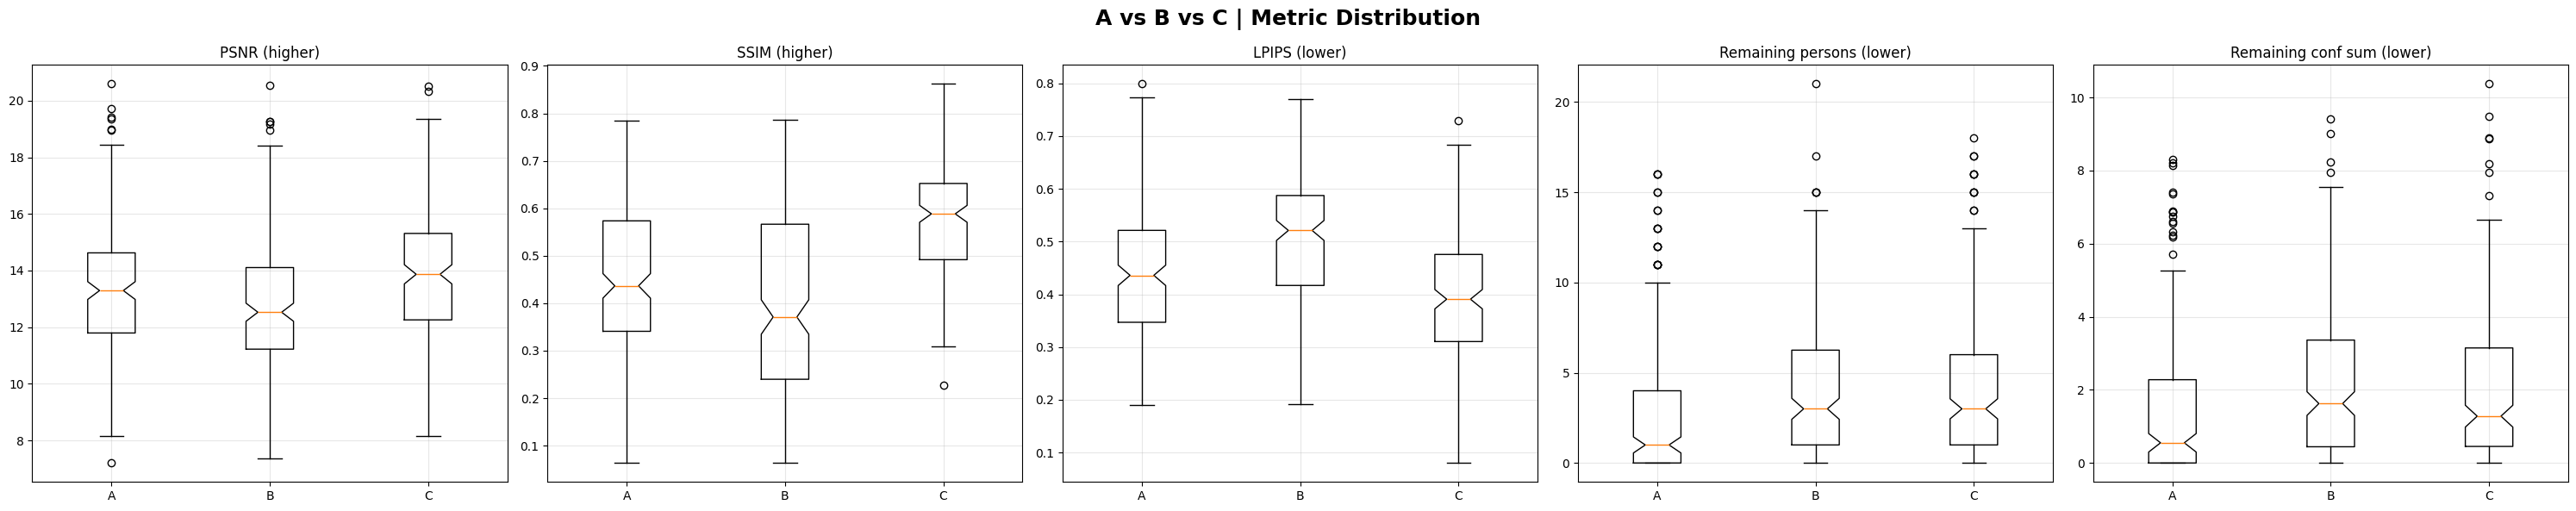

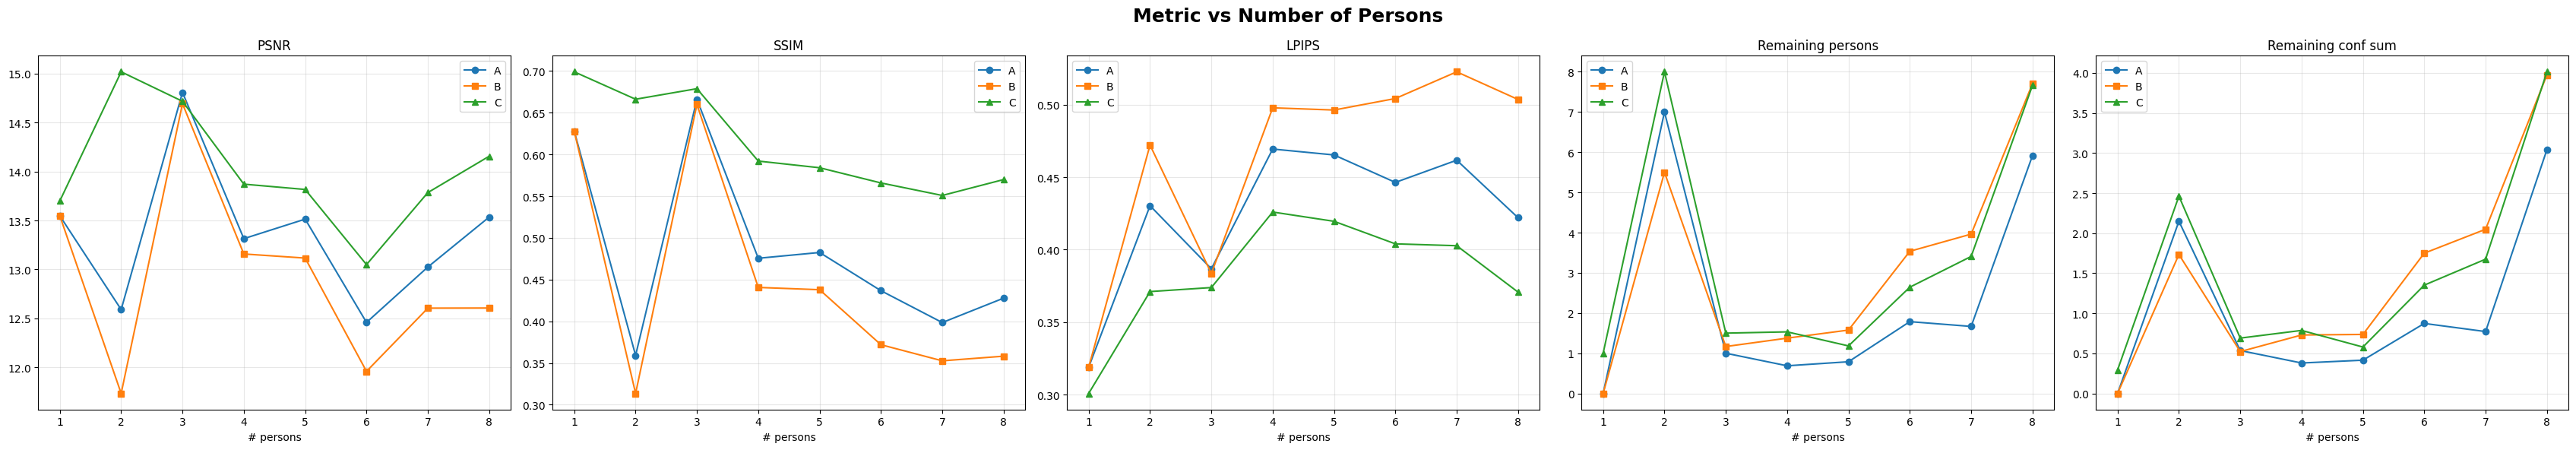

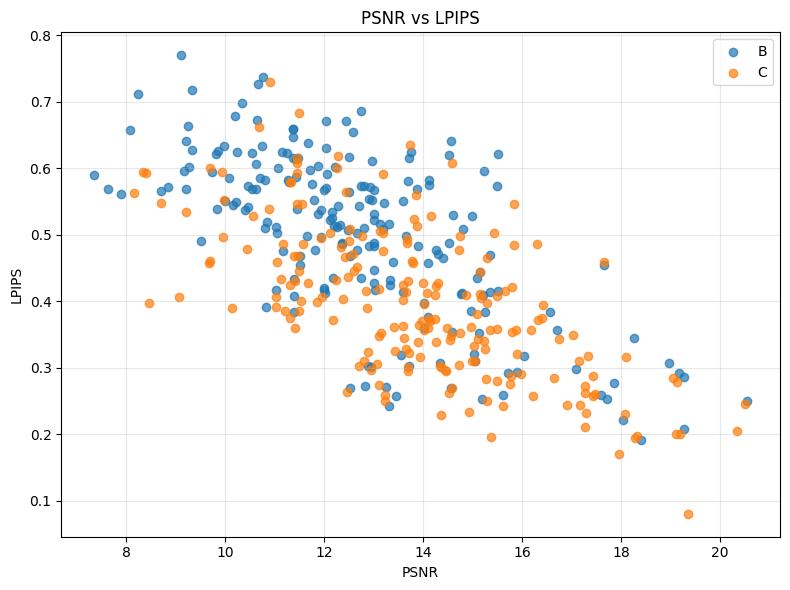

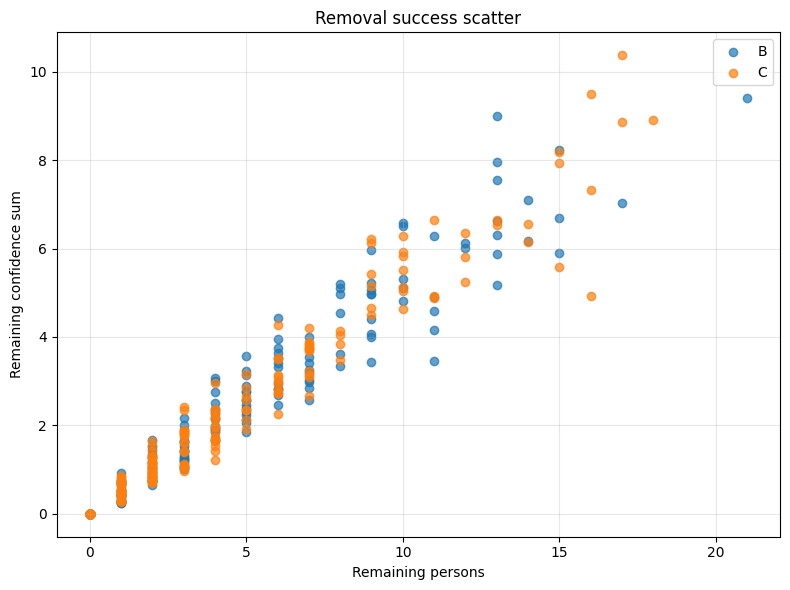

In [23]:
df = pd.read_csv(RESULTS_CSV)

# -------- Boxplots --------
fig, axes = plt.subplots(1, 5, figsize=(30, 6))
fig.suptitle("A vs B vs C | Metric Distribution", fontsize=18, fontweight="bold")

axes[0].boxplot([df["A_PSNR"], df["B_PSNR"], df["C_PSNR"]], labels=["A", "B", "C"], notch=True)
axes[0].set_title("PSNR (higher)")
axes[0].grid(True, alpha=0.3)

axes[1].boxplot([df["A_SSIM"], df["B_SSIM"], df["C_SSIM"]], labels=["A", "B", "C"], notch=True)
axes[1].set_title("SSIM (higher)")
axes[1].grid(True, alpha=0.3)

axes[2].boxplot([df["A_LPIPS"], df["B_LPIPS"], df["C_LPIPS"]], labels=["A", "B", "C"], notch=True)
axes[2].set_title("LPIPS (lower)")
axes[2].grid(True, alpha=0.3)

axes[3].boxplot([df["A_remaining_persons"], df["B_remaining_persons"], df["C_remaining_persons"]], labels=["A", "B", "C"], notch=True)
axes[3].set_title("Remaining persons (lower)")
axes[3].grid(True, alpha=0.3)

axes[4].boxplot([df["A_remaining_conf_sum"], df["B_remaining_conf_sum"], df["C_remaining_conf_sum"]], labels=["A", "B", "C"], notch=True)
axes[4].set_title("Remaining conf sum (lower)")
axes[4].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "boxplots_ABC.png", dpi=180, bbox_inches="tight")
plt.show()

# -------- Mean vs persons --------
grouped = df.groupby("n_persons").mean(numeric_only=True)

fig, axes = plt.subplots(1, 5, figsize=(34, 6))
fig.suptitle("Metric vs Number of Persons", fontsize=18, fontweight="bold")

axes[0].plot(grouped.index, grouped["A_PSNR"], marker='o', label="A")
axes[0].plot(grouped.index, grouped["B_PSNR"], marker='s', label="B")
axes[0].plot(grouped.index, grouped["C_PSNR"], marker='^', label="C")
axes[0].set_title("PSNR")
axes[0].set_xlabel("# persons")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(grouped.index, grouped["A_SSIM"], marker='o', label="A")
axes[1].plot(grouped.index, grouped["B_SSIM"], marker='s', label="B")
axes[1].plot(grouped.index, grouped["C_SSIM"], marker='^', label="C")
axes[1].set_title("SSIM")
axes[1].set_xlabel("# persons")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(grouped.index, grouped["A_LPIPS"], marker='o', label="A")
axes[2].plot(grouped.index, grouped["B_LPIPS"], marker='s', label="B")
axes[2].plot(grouped.index, grouped["C_LPIPS"], marker='^', label="C")
axes[2].set_title("LPIPS")
axes[2].set_xlabel("# persons")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

axes[3].plot(grouped.index, grouped["A_remaining_persons"], marker='o', label="A")
axes[3].plot(grouped.index, grouped["B_remaining_persons"], marker='s', label="B")
axes[3].plot(grouped.index, grouped["C_remaining_persons"], marker='^', label="C")
axes[3].set_title("Remaining persons")
axes[3].set_xlabel("# persons")
axes[3].grid(True, alpha=0.3)
axes[3].legend()

axes[4].plot(grouped.index, grouped["A_remaining_conf_sum"], marker='o', label="A")
axes[4].plot(grouped.index, grouped["B_remaining_conf_sum"], marker='s', label="B")
axes[4].plot(grouped.index, grouped["C_remaining_conf_sum"], marker='^', label="C")
axes[4].set_title("Remaining conf sum")
axes[4].set_xlabel("# persons")
axes[4].grid(True, alpha=0.3)
axes[4].legend()

plt.tight_layout()
plt.savefig(PLOT_DIR / "metric_vs_persons_ABC.png", dpi=180, bbox_inches="tight")
plt.show()

# -------- Scatter: PSNR vs LPIPS for B and C --------
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["B_PSNR"], df["B_LPIPS"], alpha=0.7, label="B")
ax.scatter(df["C_PSNR"], df["C_LPIPS"], alpha=0.7, label="C")
ax.set_xlabel("PSNR")
ax.set_ylabel("LPIPS")
ax.set_title("PSNR vs LPIPS")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "scatter_psnr_lpips_BC.png", dpi=180, bbox_inches="tight")
plt.show()

# -------- Scatter: remaining persons vs remaining conf --------
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["B_remaining_persons"], df["B_remaining_conf_sum"], alpha=0.7, label="B")
ax.scatter(df["C_remaining_persons"], df["C_remaining_conf_sum"], alpha=0.7, label="C")
ax.set_xlabel("Remaining persons")
ax.set_ylabel("Remaining confidence sum")
ax.set_title("Removal success scatter")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "scatter_removal_success_BC.png", dpi=180, bbox_inches="tight")
plt.show()


In [24]:
df = pd.read_csv(RESULTS_CSV)

# Better score = better proxy metrics + better removal success
df["improvement_score"] = (
    df["dPSNR_C_minus_B"]
    + 15.0 * df["dSSIM_C_minus_B"]
    - 10.0 * df["dLPIPS_C_minus_B"]
    - 2.0 * df["dRemainPersons_C_minus_B"]
    - 1.0 * df["dRemainConf_C_minus_B"]
)

best_rows = df.sort_values("improvement_score", ascending=False).head(NUM_VISUAL_SAMPLES_BEST)
worst_rows = df.sort_values("improvement_score", ascending=True).head(NUM_VISUAL_SAMPLES_WORST)
rand_rows = df.sample(min(NUM_VISUAL_SAMPLES_RANDOM, len(df)), random_state=SEED)

selected_stems = set(
    best_rows["image"].tolist() +
    worst_rows["image"].tolist() +
    rand_rows["image"].tolist()
)
print("Selected visuals:", len(selected_stems))

for stem in tqdm(selected_stems):
    img_path = None
    for p in all_images:
        if Path(p).stem == stem:
            img_path = p
            break

    if img_path is None:
        continue

    image_rgb = read_rgb(img_path)
    persons = detect_and_segment(image_rgb)
    if len(persons) == 0:
        continue

    outA = method_A_single_shot_global(image_rgb, persons, best_cfg)
    outB = method_B_progressive_global(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outC = method_C_progressive_local(image_rgb, persons, best_cfg, sort_strategy="largest_first")

    mA = compute_metrics(image_rgb, outA["result"], outA["union_mask"])
    mB = compute_metrics(image_rgb, outB["result"], outB["union_mask"])
    mC = compute_metrics(image_rgb, outC["result"], outC["union_mask"])

    save_path = VIS_DIR / f"{stem}_ABC_compare.png"
    save_visual_grid(stem, image_rgb, persons, outA, outB, outC, mA, mB, mC, save_path)

print("Selected visuals saved to:", VIS_DIR)


Selected visuals: 28


  0%|          | 0/28 [00:00<?, ?it/s]

Selected visuals saved to: /content/cse498r_instance_removal_week_update/outputs/selected_visuals


Demo image: /content/cse498r_instance_removal_week_update/data/dataset_extracted/000000001000.jpg
Detected persons: 8


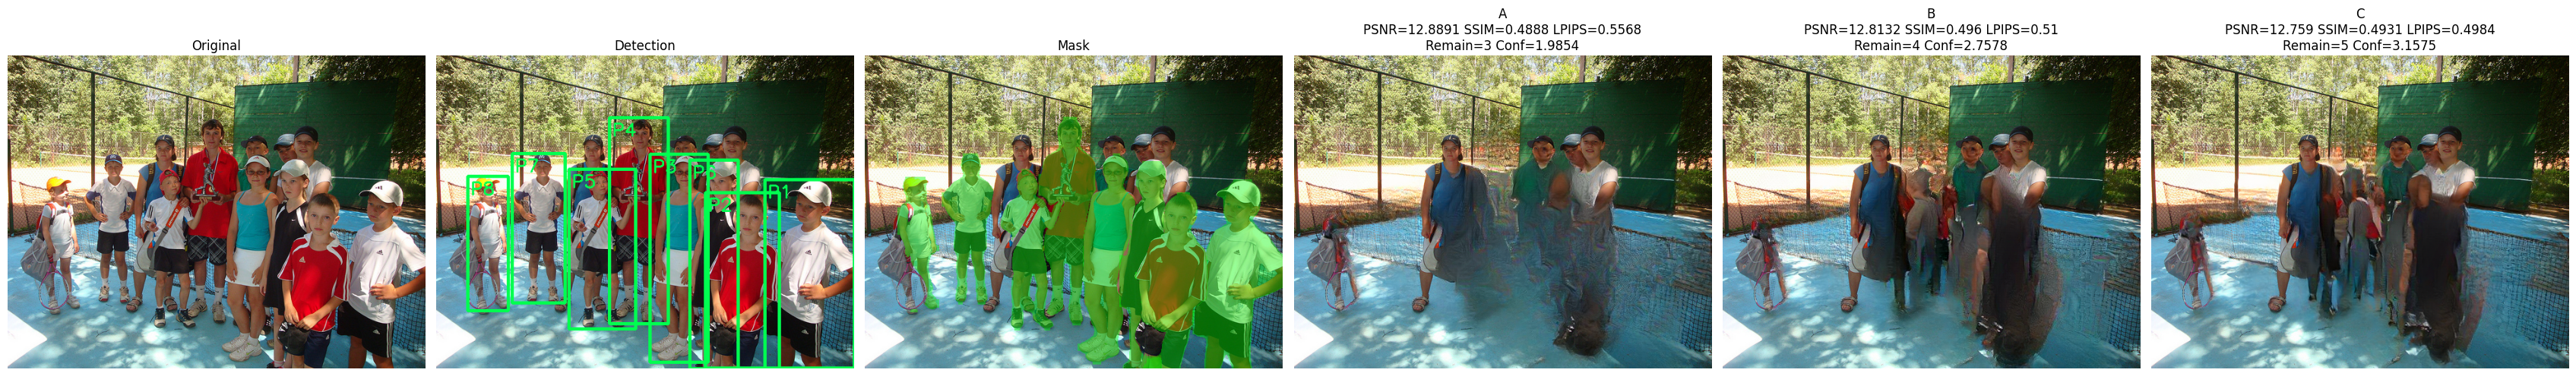

In [26]:
demo_path = str(all_images[0])   # or any index like all_images[10]

image_rgb = read_rgb(demo_path)
persons = detect_and_segment(image_rgb)

print("Demo image:", demo_path)
print("Detected persons:", len(persons))

if len(persons) == 0:
    plt.figure(figsize=(8, 6))
    plt.imshow(image_rgb)
    plt.title("No person detected")
    plt.axis("off")
    plt.show()
else:
    outA = method_A_single_shot_global(image_rgb, persons, best_cfg)
    outB = method_B_progressive_global(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outC = method_C_progressive_local(image_rgb, persons, best_cfg, sort_strategy="largest_first")

    mA = compute_metrics(image_rgb, outA["result"], outA["union_mask"])
    mB = compute_metrics(image_rgb, outB["result"], outB["union_mask"])
    mC = compute_metrics(image_rgb, outC["result"], outC["union_mask"])

    rA = residual_person_score(outA["result"])
    rB = residual_person_score(outB["result"])
    rC = residual_person_score(outC["result"])

    det = overlay_detections(image_rgb, persons)
    seg = overlay_mask(image_rgb, persons)

    fig, axes = plt.subplots(1, 6, figsize=(34, 6))
    axes[0].imshow(image_rgb); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(det); axes[1].set_title("Detection"); axes[1].axis("off")
    axes[2].imshow(seg); axes[2].set_title("Mask"); axes[2].axis("off")
    axes[3].imshow(outA["result"]); axes[3].set_title(f"A\nPSNR={mA['PSNR']} SSIM={mA['SSIM']} LPIPS={mA['LPIPS']}\nRemain={rA['remaining_persons']} Conf={rA['remaining_conf_sum']}"); axes[3].axis("off")
    axes[4].imshow(outB["result"]); axes[4].set_title(f"B\nPSNR={mB['PSNR']} SSIM={mB['SSIM']} LPIPS={mB['LPIPS']}\nRemain={rB['remaining_persons']} Conf={rB['remaining_conf_sum']}"); axes[4].axis("off")
    axes[5].imshow(outC["result"]); axes[5].set_title(f"C\nPSNR={mC['PSNR']} SSIM={mC['SSIM']} LPIPS={mC['LPIPS']}\nRemain={rC['remaining_persons']} Conf={rC['remaining_conf_sum']}"); axes[5].axis("off")
    plt.tight_layout()
    plt.show()


In [27]:
# Copy only important files
important_files = [
    RESULTS_CSV,
    SUMMARY_JSON,
]

if TUNE_CSV.exists():
    important_files.append(TUNE_CSV)

for f in important_files:
    if Path(f).exists():
        dst = DRIVE_OUT / Path(f).name
        shutil.copy2(f, dst)

# Copy plots
drive_plot_dir = DRIVE_OUT / "plots"
drive_plot_dir.mkdir(parents=True, exist_ok=True)
for f in PLOT_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, drive_plot_dir / f.name)

# Copy selected visuals only
drive_vis_dir = DRIVE_OUT / "selected_visuals"
drive_vis_dir.mkdir(parents=True, exist_ok=True)
for f in VIS_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, drive_vis_dir / f.name)

print("Copied important outputs to Drive.")
print("Drive folder:", DRIVE_OUT)


Copied important outputs to Drive.
Drive folder: /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs


In [28]:
FINAL_ZIP = DRIVE_OUT / "final_outputs_ABC.zip"

with zipfile.ZipFile(FINAL_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in important_files:
        f = Path(f)
        if f.exists():
            zf.write(f, arcname=f.name)

    for f in PLOT_DIR.glob("*"):
        if f.is_file():
            zf.write(f, arcname=f"plots/{f.name}")

    for f in VIS_DIR.glob("*"):
        if f.is_file():
            zf.write(f, arcname=f"selected_visuals/{f.name}")

print("Final zip saved to:", FINAL_ZIP)


Final zip saved to: /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs/final_outputs_ABC.zip
